In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("/content/data.csv")

In [11]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
df.shape

(7043, 21)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [14]:
df[df.TotalCharges==" "]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


- customer id has no relavance to the prediction
- Total charges coloumn is in object format
- The data is missing in total charges

In [15]:
df.drop(columns=["customerID"],inplace=True)

In [16]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

In [18]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
df["TotalCharges"]=df.TotalCharges.fillna(0)

In [20]:
df[df["TotalCharges"]==" "]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [21]:
df.isna().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


# 2. Exploratory Data Analysis (EDA)

We explore three primary dimensions driving customer churn:
1. **Target Class Distribution**: Overall churn rate baseline.
2. **Numerical Metrics**: How `tenure`, `MonthlyCharges`, and `TotalCharges` correlate with churn.
3. **Contract & Payment Features**: The impact of contract length and billing methods.

### EDA Interpretation
- The dataset contains **7,043 customers and 21 columns**.
- `customerID` is an identifier and does not provide useful predictive information, so it is removed.
- `TotalCharges` is stored as an object instead of a numeric variable and contains blank values for customers with zero tenure. Since `TotalCharges` is also strongly related to tenure and overlaps with cumulative billing information, it is removed from the final feature set.
- The target `Churn` is binary, with `Yes = 1` and `No = 0`.


## Univariant Analysis


In [22]:
numerical_columns = df.select_dtypes(include='number').columns
numerical_columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [23]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


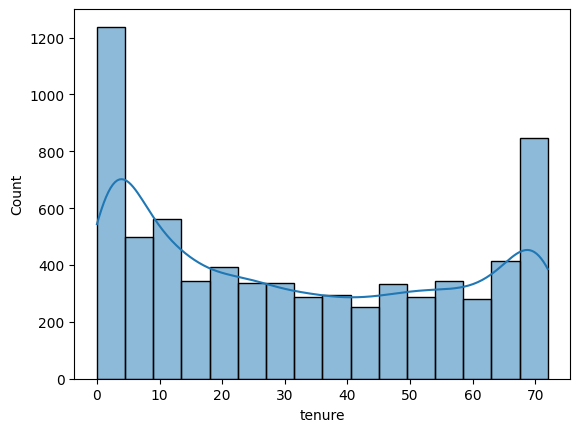

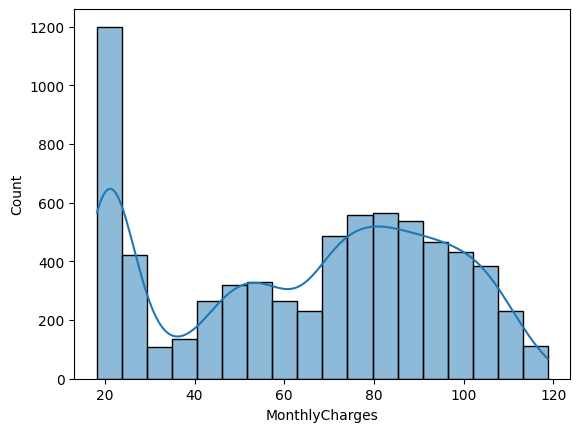

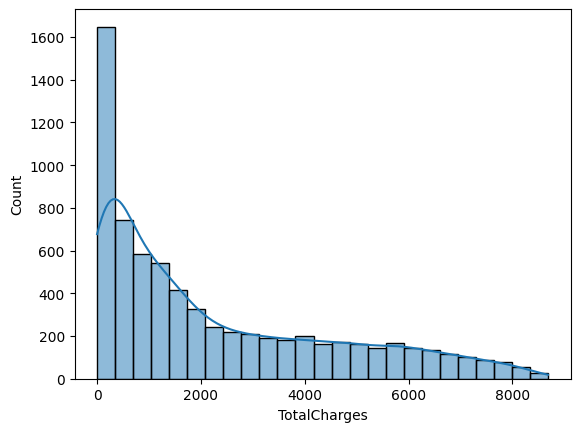

In [24]:
for i in numerical_columns[1:4]:
  sns.histplot(data=df,x=i,kde=True)
  plt.show()

In [25]:
df.groupby("Churn")[numerical_columns[1:4]].agg(["mean","median"])

tenure        MonthlyCharges         TotalCharges          
            mean median           mean  median         mean    median
Churn                                                                
No     37.569965   38.0      61.265124  64.425  2549.911442  1679.525
Yes    17.979133   10.0      74.441332  79.650  1531.796094   703.550

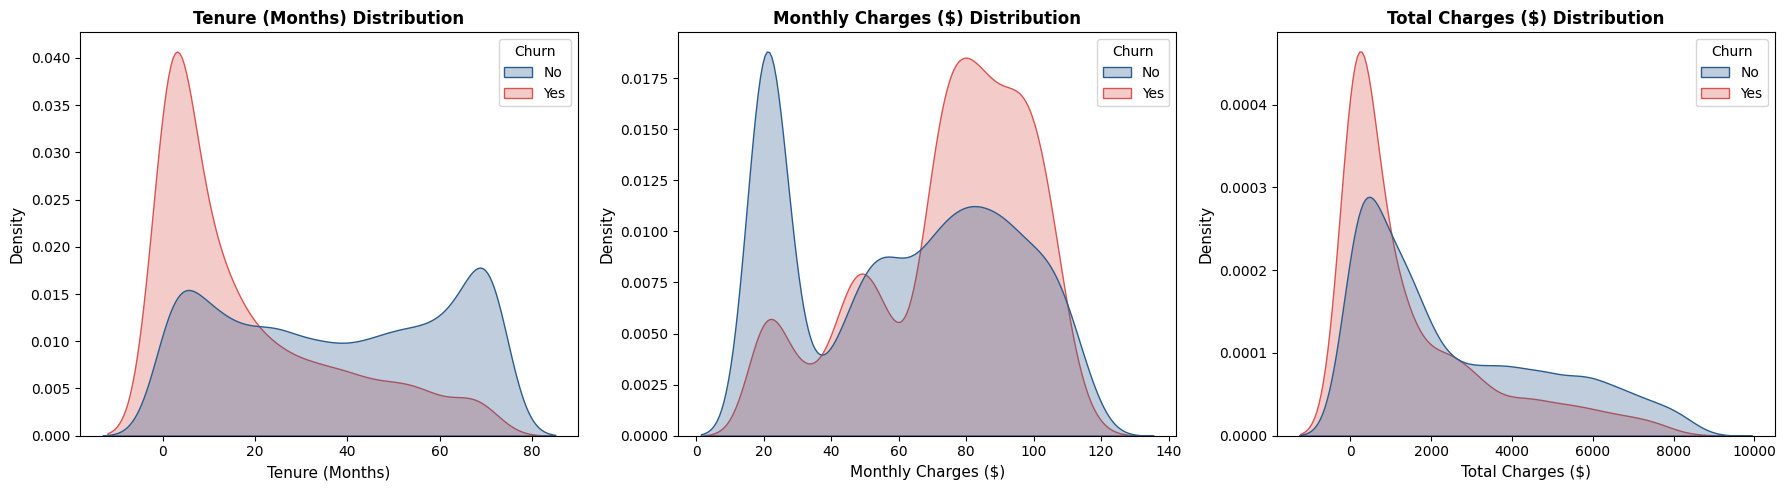

In [26]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
titles = ['Tenure (Months)', 'Monthly Charges ($)', 'Total Charges ($)']

for ax, col, title in zip(axes, num_cols, titles):
    sns.kdeplot(data=df, x=col, hue='Churn', common_norm=False,
                palette=['#2b5c8f', '#d9534f'], fill=True, alpha=0.3, ax=ax)
    ax.set_title(f'{title} Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel(title, fontsize=11)
    ax.set_ylabel('Density', fontsize=11)

plt.tight_layout()
plt.show()

### Numerical Feature Interpretation
- Customers who churn have a much lower average tenure (**17.98 months**) than customers who stay (**37.57 months**).
- Churned customers have higher average monthly charges (**74.44**) than non-churned customers (**61.27**).
- The median tenure is also substantially lower for churned customers (**10 months vs 38 months**), indicating that early-stage customers are an important churn-risk group.


In [27]:
bins = [0, 12, 24, 36, 48, 60, 72]

labels = [
    "0-12 Months",
    "13-24 Months",
    "25-36 Months",
    "37-48 Months",
    "49-60 Months",
    "61-72 Months"
]

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)


In [28]:

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [29]:
churn_rate = df.groupby("tenure_group")["Churn"].mean()*100

/tmp/ipykernel_2669/2338435822.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_rate = df.groupby("tenure_group")["Churn"].mean()*100


In [30]:
churn_rate

,Churn
tenure_group,
0-12 Months,47.438243
13-24 Months,28.710938
25-36 Months,21.634615
37-48 Months,19.028871
49-60 Months,14.423077
61-72 Months,6.609808


### Tenure-group Interpretation
- Churn decreases consistently as tenure increases.
- The churn rate is approximately **47.4%** for customers with 0–12 months of tenure, compared with only **6.6%** for customers with 61–72 months.
- This suggests that customer retention efforts may be particularly relevant during the early customer lifecycle.


In [31]:
categorical_columns = df.select_dtypes(include='object').columns

In [32]:
categorical_columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [33]:
df.drop(columns="tenure_group", inplace=True)

In [34]:
for col in categorical_columns:
  print(f"churn rate by {col} : ")
  print((df.groupby(col)["Churn"].mean()*100).round(1).sort_values(ascending=False))
  print()

churn rate by gender : 
gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64

churn rate by Partner : 
Partner
No     33.0
Yes    19.7
Name: Churn, dtype: float64

churn rate by Dependents : 
Dependents
No     31.3
Yes    15.5
Name: Churn, dtype: float64

churn rate by PhoneService : 
PhoneService
Yes    26.7
No     24.9
Name: Churn, dtype: float64

churn rate by MultipleLines : 
MultipleLines
Yes                 28.6
No                  25.0
No phone service    24.9
Name: Churn, dtype: float64

churn rate by InternetService : 
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64

churn rate by OnlineSecurity : 
OnlineSecurity
No                     41.8
Yes                    14.6
No internet service     7.4
Name: Churn, dtype: float64

churn rate by OnlineBackup : 
OnlineBackup
No                     39.9
Yes                    21.5
No internet service     7.4
Name: Churn, dtype: float64

churn rate by DeviceProtection : 

### Categorical Feature Interpretation
- Contract type shows a large difference in churn: month-to-month customers have a churn rate of **42.7%**, compared with **11.3%** for one-year contracts and **2.8%** for two-year contracts.
- Customers using **electronic check** have a churn rate of **45.3%**, the highest among the payment methods in this dataset.
- Customers without online security or technical support show substantially higher churn rates than customers who have these services.
- Fiber-optic customers have a higher observed churn rate (**41.9%**) than DSL customers (**19.0%**) or customers without internet service (**7.4%**).
- These are descriptive associations from the dataset; they should not be interpreted as proof that a feature directly causes churn.


In [35]:
df = df.replace({'No internet service': 'No', 'No phone service': 'No'})

## MultiVariantAnalysis

In [36]:
pd.crosstab(
    df["InternetService"],
    df["Contract"],
    values=df["Churn"],
    aggfunc="mean"
) * 100

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,32.215863,9.298246,1.910828
Fiber optic,54.605263,19.294991,7.226107
No,18.893130,2.472527,0.783699


### Multivariate Interpretation
- The combination of **Fiber optic + month-to-month contract** has an observed churn rate of about **54.6%**.
- The lowest observed rates occur among customers with longer contracts, especially two-year contracts.
- This interaction suggests that churn risk is not determined by a single feature alone; customer service type and contract commitment can occur together.


In [37]:
pd.crosstab(df["InternetService"], df["TechSupport"],
             values=df["Churn"], aggfunc="mean") * 100

TechSupport,No,Yes
InternetService,,
DSL,27.755430,9.677419
Fiber optic,49.372197,22.632794
No,7.404980,NaN


### Internet Service and Technical Support
- Among fiber-optic customers, the observed churn rate is about **49.4% without technical support** versus **22.6% with technical support**.
- This is an association in the observed data, not a causal conclusion.


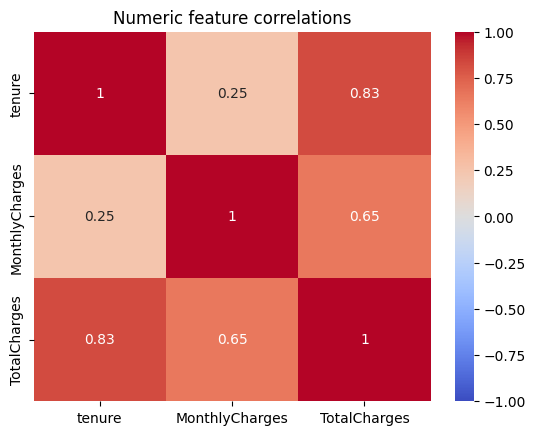

In [38]:
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr(),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Numeric feature correlations")
plt.show()


Dropping TotalCharges

In [39]:

df.drop(columns='TotalCharges',inplace =True)

In [40]:
# Binary columns
binary_cols = [
    "gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling",
    "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]

binary_map = {
    "Yes": 1,
    "No": 0,
    "Male": 1,
    "Female": 0
}

for col in binary_cols:
    df[col] = df[col].map(binary_map)

In [41]:
categorical_cols = [
    "InternetService",
    "Contract",
    "PaymentMethod"
]

numerical_cols = [
    "tenure",
    "MonthlyCharges"
]

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(drop="first", handle_unknown="ignore"),
         categorical_cols),

        ("numerical",
         StandardScaler(),
         numerical_cols)
    ],
    remainder="passthrough"
)

In [43]:

X = df.drop("Churn", axis=1)

y = df["Churn"]

In [44]:

from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [50]:

from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

In [49]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric="logloss"
    ))
])

In [51]:

models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Random Forest trained
XGBoost trained


In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall   :", recall_score(y_test, y_pred))
    print("F1       :", f1_score(y_test, y_pred))
    print("ROC-AUC  :", roc_auc_score(y_test, y_prob))


Logistic Regression
Accuracy : 0.7558552164655784
Precision: 0.5248713550600344
Recall   : 0.8203753351206434
F1       : 0.6401673640167364
ROC-AUC  : 0.8604720672415043

Random Forest
Accuracy : 0.7934705464868701
Precision: 0.6507352941176471
Recall   : 0.4745308310991957
F1       : 0.5488372093023256
ROC-AUC  : 0.8395522581179417

XGBoost
Accuracy : 0.8097941802696949
Precision: 0.6755852842809364
Recall   : 0.5415549597855228
F1       : 0.6011904761904762
ROC-AUC  : 0.860045079549101


### Baseline Model Comparison
- Logistic Regression gives the highest recall among the three baseline models (**82.0%**) and a ROC-AUC of about **0.860**.
- Random Forest has higher accuracy (**79.3%**) but lower recall (**47.5%**).
- XGBoost has the highest accuracy (**81.0%**) and precision (**67.6%**) in this baseline comparison, but its recall (**54.2%**) is considerably lower than Logistic Regression.
- For churn prediction, recall is important when the objective is to identify as many potentially churning customers as possible. Logistic Regression also provides directly interpretable coefficients, which supports the final model choice.
- Therefore, Logistic Regression is retained as the final model, while hyperparameter tuning and threshold tuning are performed before the final test evaluation.


# Hyperparameter Tuning - Logistic Regression

The baseline Logistic Regression model used `class_weight='balanced'` and `max_iter=1000`. We now tune the regularization strength `C`, solver, and class-weight strategy using cross-validation on the training data only.

**Important:** The test set is not used during hyperparameter tuning. This keeps the final test score as an unbiased estimate of performance on unseen data.


In [ ]:
from sklearn.model_selection import GridSearchCV

lr_tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42))
])

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs'],
    'classifier__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=lr_tuning_pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best CV ROC-AUC:', grid_search.best_score_)


### Why tune `C` and `class_weight`?
- `C` controls the strength of regularization. Smaller values apply stronger regularization and can reduce overfitting.
- `class_weight='balanced'` gives more importance to the minority churn class and can improve detection of churners.
- ROC-AUC is used for tuning because it evaluates the quality of probability ranking independently of one fixed classification threshold.


# Threshold Tuning

Logistic Regression produces a probability of churn. The default threshold of 0.50 is not mandatory. We select a threshold using a validation split from the training data, then evaluate that chosen threshold once on the untouched test set.

Here, **F1-score** is used as the threshold-selection criterion because it balances precision and recall. If the business later assigns a higher cost to missing a churner, the threshold can instead be selected using a recall constraint or an explicit cost function.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

# Split the original training data into a model-training part and a validation part.
X_model, X_val, y_model, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Refit the best hyperparameter configuration on the model-training portion.
tuned_lr = grid_search.best_estimator_
tuned_lr.fit(X_model, y_model)

val_prob = tuned_lr.predict_proba(X_val)[:, 1]

threshold_results = []
thresholds = np.arange(0.20, 0.81, 0.01)

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)
    threshold_results.append({
        'threshold': threshold,
        'accuracy': accuracy_score(y_val, val_pred),
        'precision': precision_score(y_val, val_pred, zero_division=0),
        'recall': recall_score(y_val, val_pred, zero_division=0),
        'f1': f1_score(y_val, val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
best_threshold = threshold_df.loc[threshold_df['f1'].idxmax(), 'threshold']

print('Best threshold based on validation F1:', round(best_threshold, 2))
display(threshold_df.sort_values('f1', ascending=False).head(10))


In [ ]:
# Visualize the threshold trade-off on the validation set.
plt.figure(figsize=(10, 5))
plt.plot(threshold_df['threshold'], threshold_df['precision'], label='Precision')
plt.plot(threshold_df['threshold'], threshold_df['recall'], label='Recall')
plt.plot(threshold_df['threshold'], threshold_df['f1'], label='F1-score')
plt.axvline(best_threshold, linestyle='--', label=f'Chosen threshold = {best_threshold:.2f}')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Tuning on Validation Data')
plt.legend()
plt.show()


# Final Logistic Regression Evaluation

After selecting the hyperparameters and threshold using training/validation data, the final model is evaluated on the untouched test set. This is the performance that should be reported as the final model result.


In [ ]:
# Fit the tuned Logistic Regression using the complete training set.
final_lr = grid_search.best_estimator_
final_lr.fit(X_train, y_train)

test_prob = final_lr.predict_proba(X_test)[:, 1]
test_pred_default = (test_prob >= 0.50).astype(int)
test_pred_tuned = (test_prob >= best_threshold).astype(int)

print('--- Default threshold: 0.50 ---')
print('Accuracy :', accuracy_score(y_test, test_pred_default))
print('Precision:', precision_score(y_test, test_pred_default, zero_division=0))
print('Recall   :', recall_score(y_test, test_pred_default, zero_division=0))
print('F1       :', f1_score(y_test, test_pred_default, zero_division=0))
print('ROC-AUC  :', roc_auc_score(y_test, test_prob))

print(f'\n--- Tuned threshold: {best_threshold:.2f} ---')
print('Accuracy :', accuracy_score(y_test, test_pred_tuned))
print('Precision:', precision_score(y_test, test_pred_tuned, zero_division=0))
print('Recall   :', recall_score(y_test, test_pred_tuned, zero_division=0))
print('F1       :', f1_score(y_test, test_pred_tuned, zero_division=0))
print('ROC-AUC  :', roc_auc_score(y_test, test_prob))


# Logistic Regression Interpretability

Logistic Regression is retained as the final model because its coefficients can be inspected directly. A positive coefficient increases the model's log-odds of churn, while a negative coefficient decreases them, holding the other encoded features constant.

The coefficient table below helps explain which encoded customer characteristics are associated with higher or lower predicted churn risk.


In [ ]:
feature_names = final_lr.named_steps['preprocessor'].get_feature_names_out()
coefficients = final_lr.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'odds_ratio': np.exp(coefficients)
})

coef_df['absolute_coefficient'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('absolute_coefficient', ascending=False)

display(coef_df[['feature', 'coefficient', 'odds_ratio']].head(20))


# Final Conclusion

- Logistic Regression was selected as the final model based on its strong churn recall/ROC-AUC performance in the baseline comparison and its direct interpretability.
- Hyperparameter tuning is performed with 5-fold cross-validation on the training data.
- The classification threshold is tuned separately on validation data rather than assuming 0.50 is optimal.
- The final threshold and hyperparameters are then evaluated once on the untouched test set.
- The coefficient/odds-ratio table provides an interpretable explanation of the model's predictions.
